__aims:__

Identify cell types through combining our data with a reference dataset.

__minor changes:__
- I do not exclude female this time! So I can annotate cell types for all samples at the same time.

__tasks:__

- [x] Gather data for nucleus-accumbens (NAs) subtypes as reference

- [ ] Train the AE model on reference data for cell type prediction on our data

- [ ] Redo our cell type identification using these predictions
___
- I asked this https://github.com/theislab/scarches/issues/185
- `SCANVI` – https://docs.scarches.org/en/latest/scanvi_surgery_pipeline.html
<!-- https://scarchest.readthedocs.io/en/latest/scanvi_surgery_pipeline.html
     -->
    <!-- https://docs.scvi-tools.org/en/stable/tutorials/notebooks/harmonization.html
    `scvi`
    https://docs.scvi-tools.org/en/stable/tutorials/notebooks/api_overview.html#Loading-and-preparing-data
    > Finally, we perform feature selection, to reduce the number of features (genes in this case) used as input to the scvi-tools model. For best practices of how/when to perform feature selection, please refer to the model-specific tutorial. For scVI, we recommend anywhere from 1,000 to 10,000 HVGs, but it will be context-dependent.
-->



### Semi-supervised surgery pipeline with SCANVI

In [73]:
import numpy as np

In [1]:
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

In [2]:
from venn import venn

In [3]:
from scarches.dataset.trvae.data_handling import remove_sparsity

import scarches as sca
import torch

torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
 captum (see https://github.com/pytorch/captum).
INFO:lightning_fabric.utilities.seed:Global seed set to 0
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(data_clz, keypaths)
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register

In [4]:
import scvi

In [5]:
import scez

scanpy==1.9.3 anndata==0.8.0 umap==0.5.3 numpy==1.23.5 scipy==1.10.1 pandas==2.0.0 scikit-learn==1.2.2 statsmodels==0.13.5 python-igraph==0.10.3 pynndescent==0.5.8


### Download Dataset and split into reference dataset and query dataset

#### NAs-subtypes

##### Download data

In [ ]:
# !wget https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_expression_matrix.csv.gz

--2023-03-27 15:14:46--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_expression_matrix.csv.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.7, 130.14.250.10
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.7|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 96453357 (92M) [application/x-gzip]
Saving to: ‘GSE118020_expression_matrix.csv.gz’

GSE118020_expressio 100%[===================>]  91.98M  2.95MB/s    in 30s     

2023-03-27 15:15:17 (3.03 MB/s) - ‘GSE118020_expression_matrix.csv.gz’ saved [96453357/96453357]



In [5]:
# !wget https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_meta_data.csv.gz

--2023-03-27 15:15:17--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE118nnn/GSE118020/suppl/GSE118020_meta_data.csv.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.10, 130.14.250.7
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1139724 (1.1M) [application/x-gzip]
Saving to: ‘GSE118020_meta_data.csv.gz’

GSE118020_meta_data 100%[===================>]   1.09M  2.32MB/s    in 0.5s    

2023-03-27 15:15:18 (2.32 MB/s) - ‘GSE118020_meta_data.csv.gz’ saved [1139724/1139724]



In [6]:
# mkdir GSE118020

In [7]:
# mv -v GSE118020_* GSE118020/

GSE118020_expression_matrix.csv.gz -> GSE118020/GSE118020_expression_matrix.csv.gz
GSE118020_meta_data.csv.gz -> GSE118020/GSE118020_meta_data.csv.gz


##### make `annData`

In [85]:
counts = pd.read_csv('GSE118020/GSE118020_expression_matrix.csv.gz',index_col=0).T

In [86]:
meta = pd.read_csv('GSE118020/GSE118020_meta_data.csv.gz',index_col=0)

https://github.com/theislab/scarches/issues/181#issuecomment-1481792842

In [87]:
adata = ad.AnnData(
    X = counts,
    obs = meta,
    dtype='float32'
)

In [88]:
adata.write_h5ad('GSE118020/GSE118020_adata.h5ad.gz')

#### Load, combine, and prepare `adata`

In [48]:
rdata = sc.read_h5ad('GSE118020/GSE118020_adata.h5ad.gz')

rdata.obs['dataset'] = 'source_data'

In [8]:
adata = sc.read_h5ad('preprocessing/adata-cleaned-v2.h5ad.gz')

adata.var_names_make_unique()

adata.obs['dataset'] = 'target_data'

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [10]:
ol_genes = list(set(adata.var.index) & set(rdata.var.index))

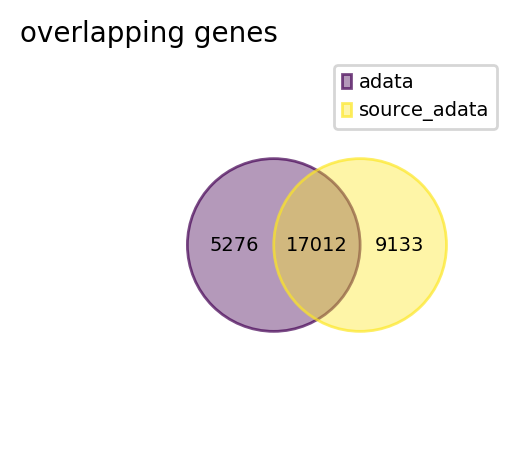

In [49]:
_, ax = plt.subplots(ncols=1, nrows=1, figsize=(12, 2.5))

venn({
    'adata':set(adata.var.index),
    'source_adata':set(rdata.var.index)
},ax=ax,fontsize=7)

plt.suptitle('overlapping genes')
plt.show()

In [50]:
cdata = sc.concat([
    adata[:,adata.var.index.isin(ol_genes)],
    rdata[:,rdata.var.index.isin(ol_genes)]
])

In [51]:
cdata = remove_sparsity(cdata)

In [52]:
cdata.obs.groupby('dataset').size()

dataset
source_data    47576
target_data    22478
dtype: int64

___

In [53]:
cdata

AnnData object with n_obs × n_vars = 70054 × 17012
    obs: 'dataset'

In [54]:
source_adata = cdata[cdata.obs['dataset'].eq('source_data')].copy()
target_adata = cdata[cdata.obs['dataset'].eq('target_data')].copy()

In [55]:
source_adata.obs = rdata.obs

In [56]:
target_adata.obs = adata.obs

In [87]:
target_adata.obs = target_adata.obs.rename(columns={'batch':'Sample'})

In [57]:
source_adata.obs.groupby('CellType').size()

CellType
Astro     7537
D1       12342
D2        7687
Endo      3516
IN        1330
Micro     3230
NB         483
OPC       3031
Oligo     8420
dtype: int64

In [58]:
target_adata.obs.groupby('cond').size()

cond
MDMA_acute_female     864
MDMA_acute_male      8070
MDMA_male            1102
Meth_male            2886
Saline_male          9556
dtype: int64

### Create SCANVI model and train it on fully labelled reference dataset

In [59]:
condition_key='Sample'
cell_type_key='CellType'

In [60]:
sca.models.SCVI.setup_anndata(source_adata, batch_key=condition_key, labels_key=cell_type_key)

In [61]:
vae = sca.models.SCVI(
    source_adata,
    n_layers=2,
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
)

In [62]:
vae.train()

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs


Epoch 168/168: 100%|██████████| 168/168 [1:58:09<00:00, 40.57s/it, loss=5.15e+03, v_num=1]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=168` reached.


Epoch 168/168: 100%|██████████| 168/168 [1:58:09<00:00, 42.20s/it, loss=5.15e+03, v_num=1]


In [63]:
scanvae = sca.models.SCANVI.from_scvi_model(vae, unlabeled_category = "Unknown")

In [64]:
print("Labelled Indices: ", len(scanvae._labeled_indices))
print("Unlabelled Indices: ", len(scanvae._unlabeled_indices))

Labelled Indices:  47576
Unlabelled Indices:  0


In [65]:
scanvae.train(max_epochs=20)

INFO     Training for 20 epochs.                                                                                   


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs


Epoch 20/20: 100%|██████████| 20/20 [17:15<00:00, 51.97s/it, loss=5.23e+03, v_num=1]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 20/20: 100%|██████████| 20/20 [17:15<00:00, 51.79s/it, loss=5.23e+03, v_num=1]


### Create anndata file of latent representation and compute UMAP


In [66]:
reference_latent = sc.AnnData(scanvae.get_latent_representation())
reference_latent.obs["cell_type"] = source_adata.obs[cell_type_key].tolist()
reference_latent.obs["batch"] = source_adata.obs[condition_key].tolist()

In [67]:
reference_latent

AnnData object with n_obs × n_vars = 47576 × 10
    obs: 'cell_type', 'batch'

In [68]:
sc.pp.neighbors(reference_latent, n_neighbors=8)

In [69]:
sc.tl.leiden(reference_latent)
sc.tl.umap(reference_latent)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


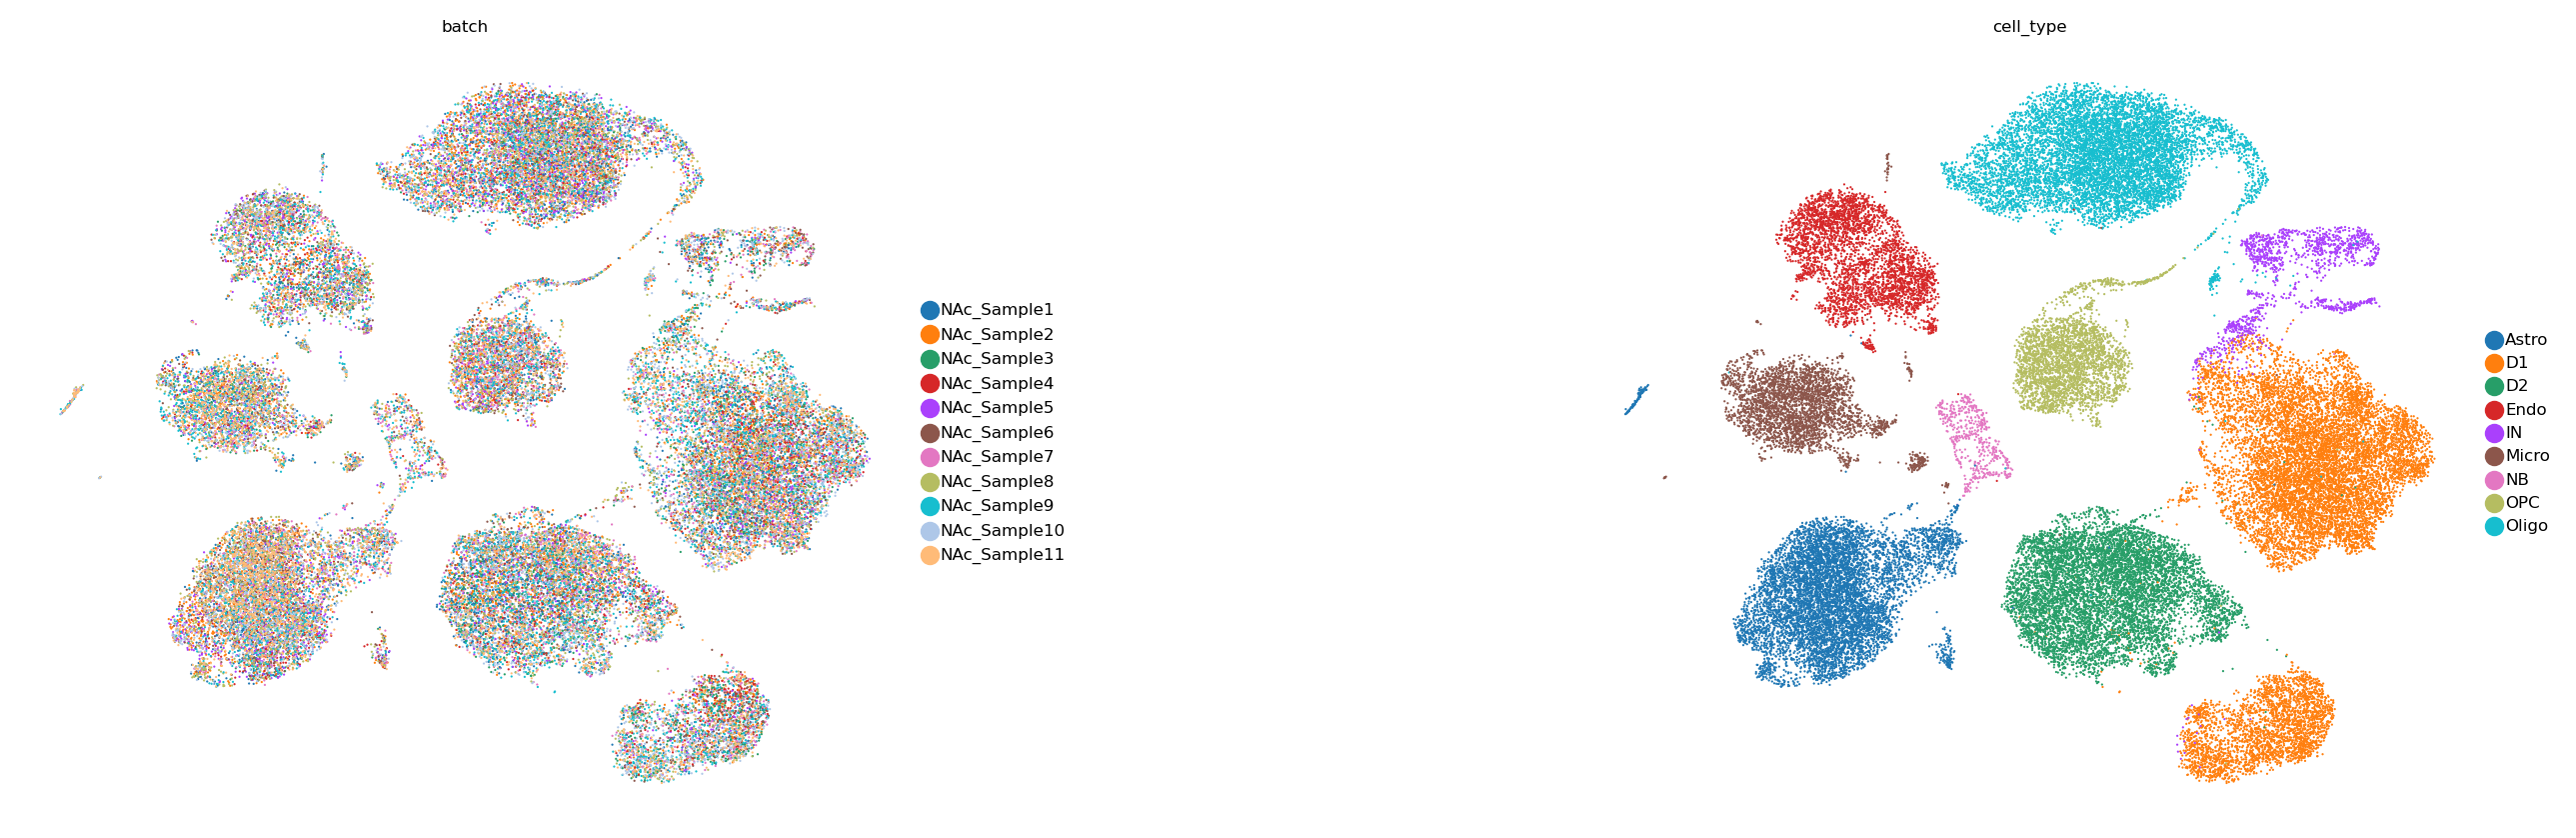

In [70]:
sc.pl.umap(reference_latent,
           color=['batch', 'cell_type'],
           frameon=False,
           wspace=0.6,
           )

In [72]:
reference_latent.obs['predictions'] = scanvae.predict()

In [74]:
print("Acc: {}".format(np.mean(reference_latent.obs.predictions == reference_latent.obs.cell_type)))

Acc: 0.997372624852867


#### Save model

In [75]:
!mkdir -p scanvi_models

In [78]:
ref_path = 'scanvi_models/09_05_2023_ref_model/'
scanvae.save(ref_path, overwrite=True)

### Perform surgery on reference model and train on query dataset without cell type labels

In [89]:
model = sca.models.SCANVI.load_query_data(
    target_adata,
    ref_path,
    freeze_dropout = True,
)
model._unlabeled_indices = np.arange(target_adata.n_obs)
model._labeled_indices = []

INFO     File scanvi_models/09_05_2023_ref_model/model.pt already downloaded                                       


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scvi/data/fields/_scanvi.py:90: UserWarning: Missing labels key CellType. Filling in with unlabeled category Unknown.
  warnings.warn(


In [90]:
print("Labelled Indices: ", len(model._labeled_indices))
print("Unlabelled Indices: ", len(model._unlabeled_indices))

Labelled Indices:  0
Unlabelled Indices:  22478


In [92]:
model.train(
    max_epochs=100,
    plan_kwargs=dict(weight_decay=0.0),
    check_val_every_n_epoch=10,
)

INFO     Training for 100 epochs.                                                                                  


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs


Epoch 100/100: 100%|██████████| 100/100 [18:20<00:00, 11.05s/it, loss=6.6e+03, v_num=1] 

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [18:20<00:00, 11.00s/it, loss=6.6e+03, v_num=1]


In [94]:
query_latent = sc.AnnData(model.get_latent_representation())
query_latent.obs['cell_type'] = target_adata.obs[cell_type_key].tolist()
query_latent.obs['batch'] = target_adata.obs[condition_key].tolist()

In [95]:
sc.pp.neighbors(query_latent)
sc.tl.leiden(query_latent)
sc.tl.umap(query_latent)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Figure size 500x500 with 0 Axes>

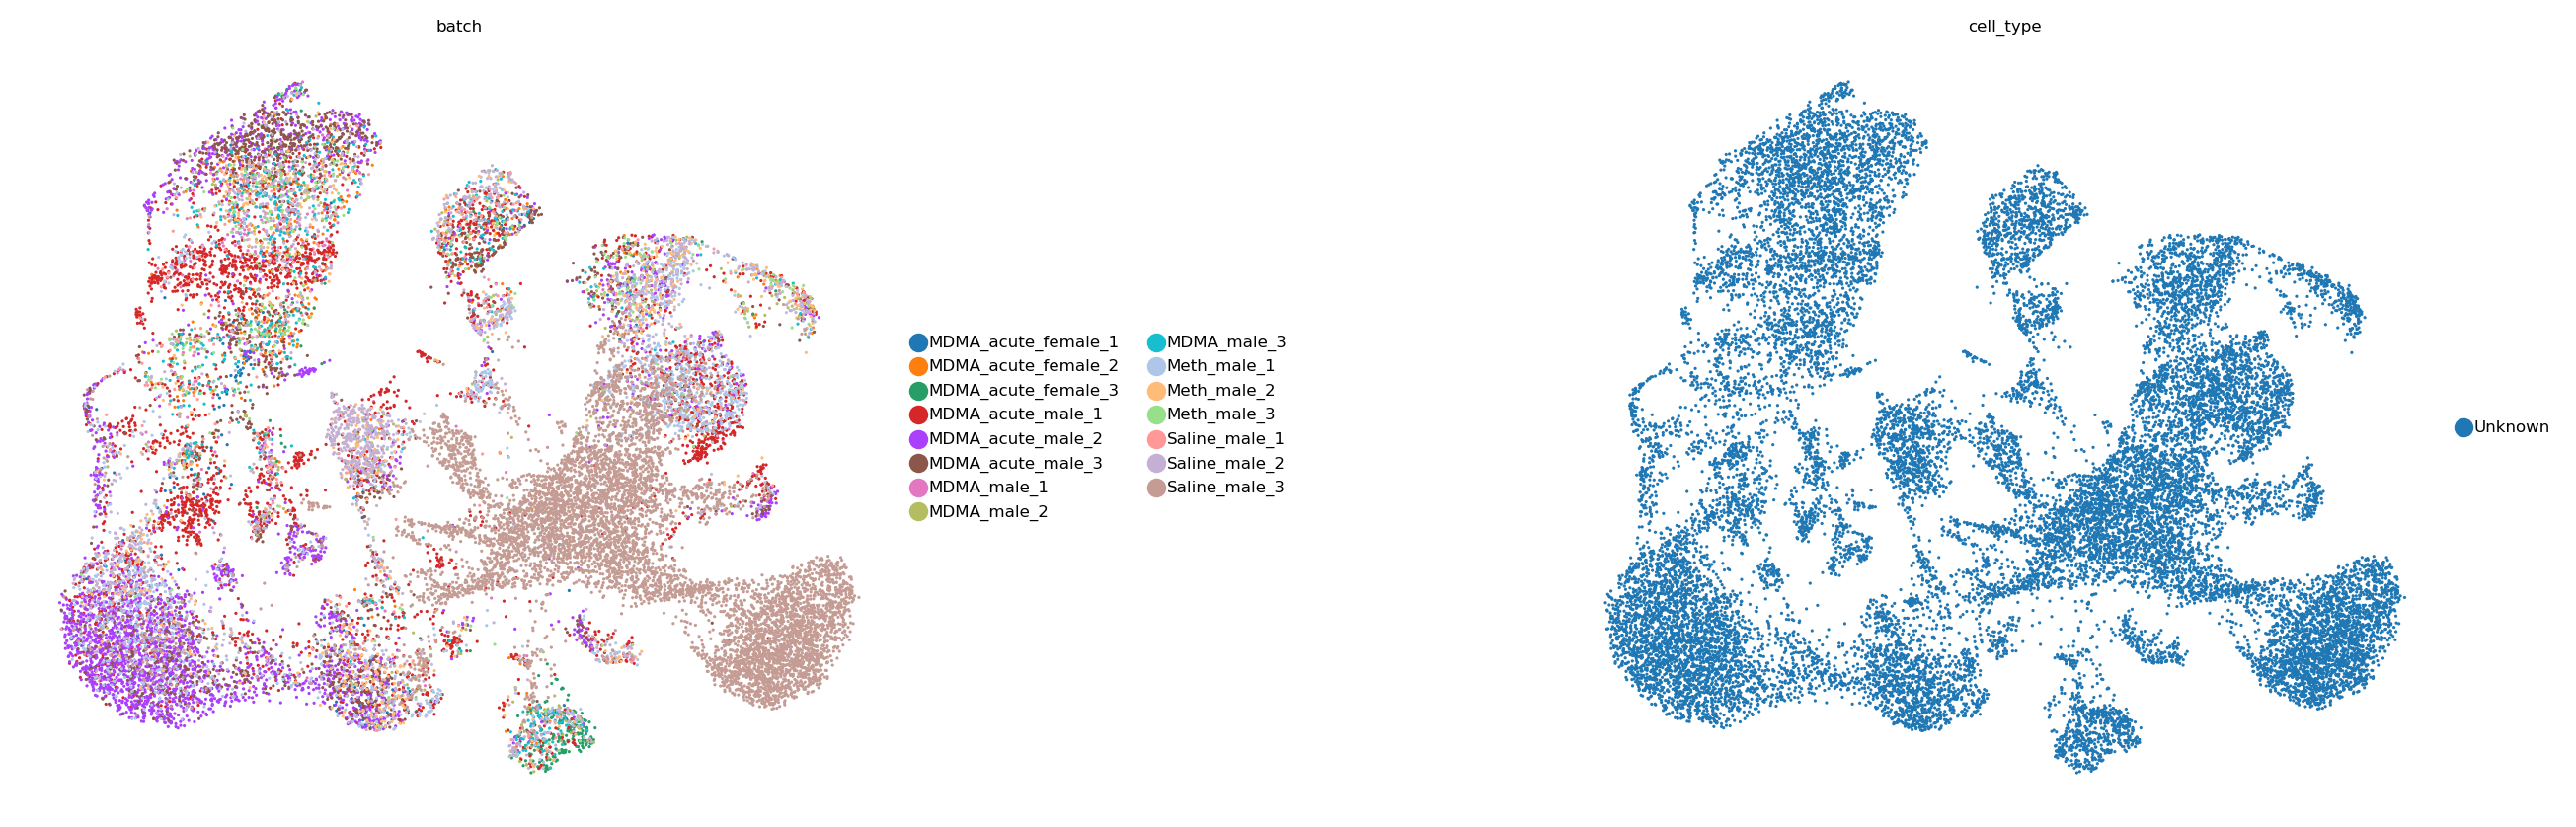

In [96]:
plt.figure()
sc.pl.umap(
    query_latent,
    color=["batch", "cell_type"],
    frameon=False,
    wspace=0.6,
)

### Save model

In [ ]:
surgery_path = 'scanvi_models/09_05_2023_surgery_model'
model.save(surgery_path, overwrite=True)


### Get latent representation of reference + query dataset and compute UMAP

In [137]:
# adata_annotated = 

In [138]:
# target_adata.obs

In [97]:
adata_full = source_adata.concatenate(target_adata)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],


In [204]:
condition_key

'Sample'

In [146]:
scez.clustering(adata_full, res=0.3)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


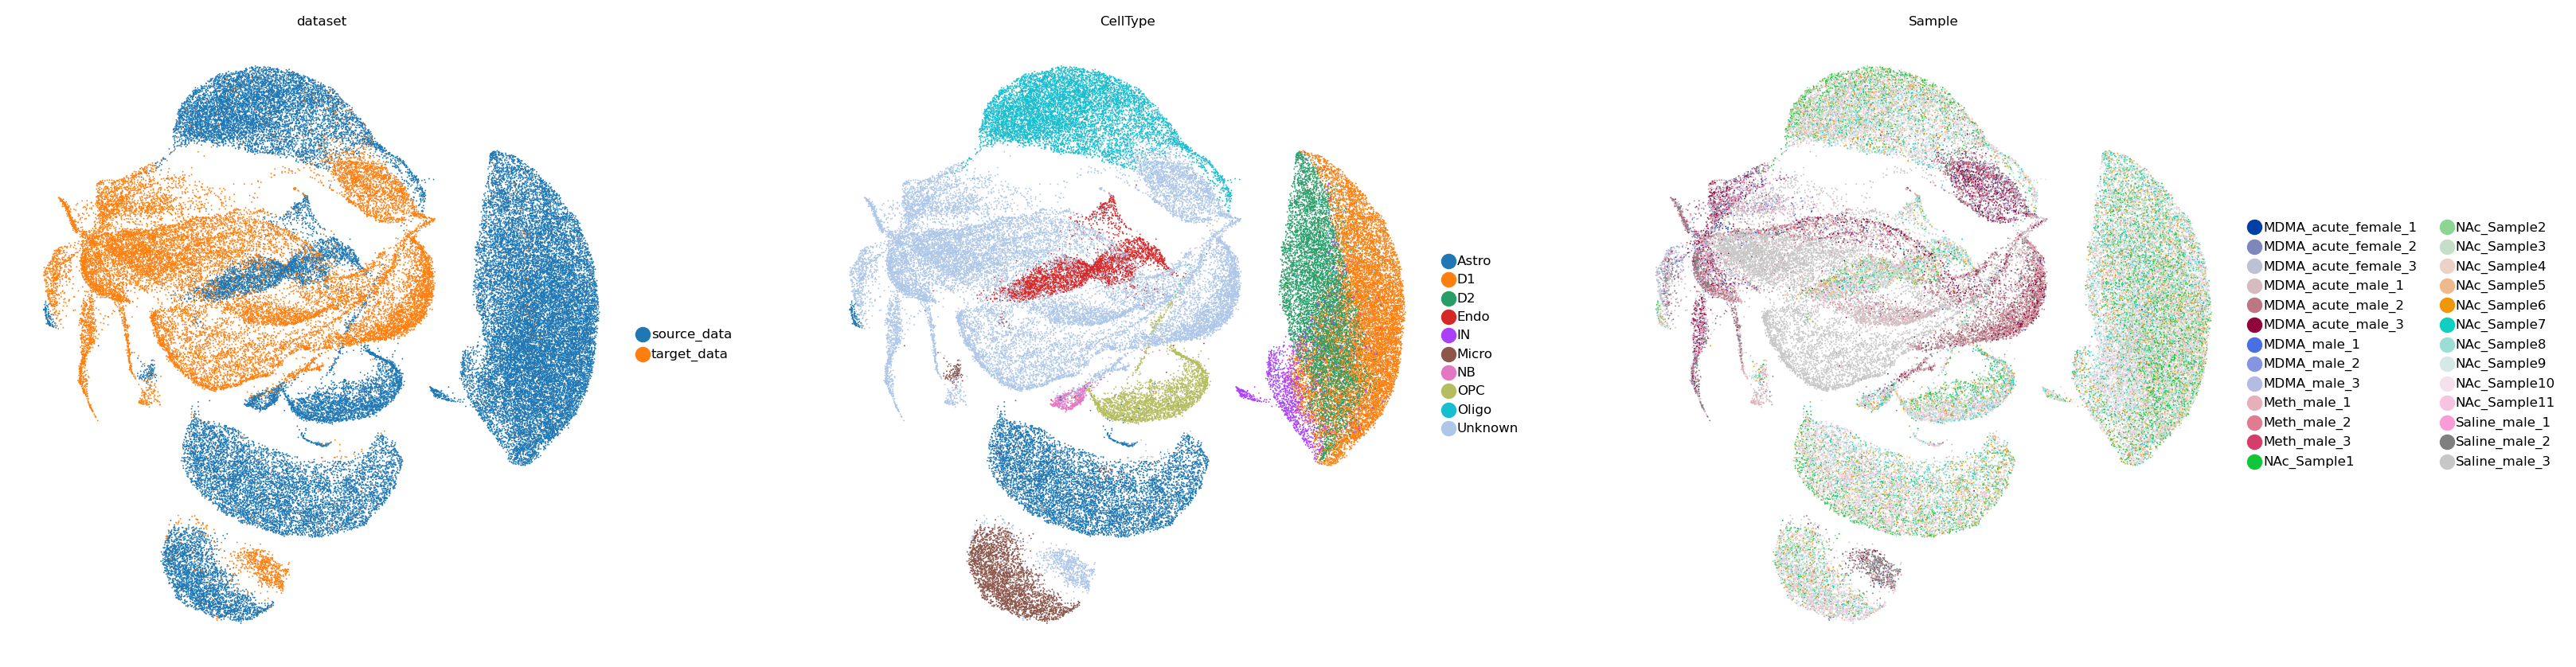

In [206]:
sc.pl.umap(
    adata_full,
    color=[
        "dataset", 
        "CellType",
        'Sample',    
    ],
    frameon=False,
    vmax=10,
    wspace=0.2,
)

In [199]:
adata_full.obs

,nGene,nUMI,orig.ident,percent.mito,Sample,tree.ident,CellType,L2_Clustering,dataset,_scvi_batch,_scvi_labels,cond,group,batch,leiden
AAACCTGAGTGAACGC.NAc_Sample1-0,2065.0,4676.0,D2_2,0.033362,NAc_Sample1,6.0,D2,D2_2,source_data,0,2,NaN,NaN,0,0
AACCGCGTCAGCTCTC.NAc_Sample1-0,2721.0,7759.0,D2_2,0.021266,NAc_Sample1,6.0,D2,D2_2,source_data,0,2,NaN,NaN,0,1
ACACCCTAGCTGAACG.NAc_Sample1-0,2387.0,5822.0,D2_2,0.020268,NAc_Sample1,6.0,D2,D2_2,source_data,0,2,NaN,NaN,0,1
CCGTGGAAGCTACCGC.NAc_Sample1-0,2656.0,6514.0,D2_2,0.027479,NAc_Sample1,6.0,D2,D2_2,source_data,0,2,NaN,NaN,0,0
CCTCAGTTCTTCCTTC.NAc_Sample1-0,2768.0,7784.0,D2_2,0.018885,NAc_Sample1,6.0,D2,D2_2,source_data,0,2,NaN,NaN,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGAGGCCTTCG-1_Saline_male_3-1,NaN,NaN,NaN,NaN,Saline_male_3,NaN,Unknown,NaN,target_data,25,9,Saline_male,Saline,1,3
TTTGTTGCACTGGCGT-1_Saline_male_3-1,NaN,NaN,NaN,NaN,Saline_male_3,NaN,Unknown,NaN,target_data,25,9,Saline_male,Saline,1,3
TTTGTTGCAGGTCCGT-1_Saline_male_3-1,NaN,NaN,NaN,NaN,Saline_male_3,NaN,Unknown,NaN,target_data,25,9,Saline_male,Saline,1,3
TTTGTTGCATCACAGT-1_Saline_male_3-1,NaN,NaN,NaN,NaN,Saline_male_3,NaN,Unknown,NaN,target_data,25,9,Saline_male,Saline,1,4


In [158]:
full_latent = sc.AnnData(model.get_latent_representation(adata=adata_full))
full_latent.obs['cell_type'] = adata_full.obs[cell_type_key].tolist()
full_latent.obs['batch'] = adata_full.obs[condition_key].tolist()

In [160]:
full_latent

AnnData object with n_obs × n_vars = 70054 × 10
    obs: 'cell_type', 'batch'

In [161]:
# sc.pp.neighbors(full_latent)
# sc.tl.leiden(full_latent)
# sc.tl.umap(full_latent)

In [162]:
scez.clustering(full_latent, n_neighbor=15 ,n_comps=2, res=0.1)

In [174]:
sc.tl.umap(full_latent,min_dist=0.3)

In [175]:
full_latent

AnnData object with n_obs × n_vars = 70054 × 10
    obs: 'cell_type', 'batch', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden', 'batch_colors', 'cell_type_colors', 'leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [190]:
full_latent.obs['dataset'] = adata_full.obs['dataset'].to_list()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


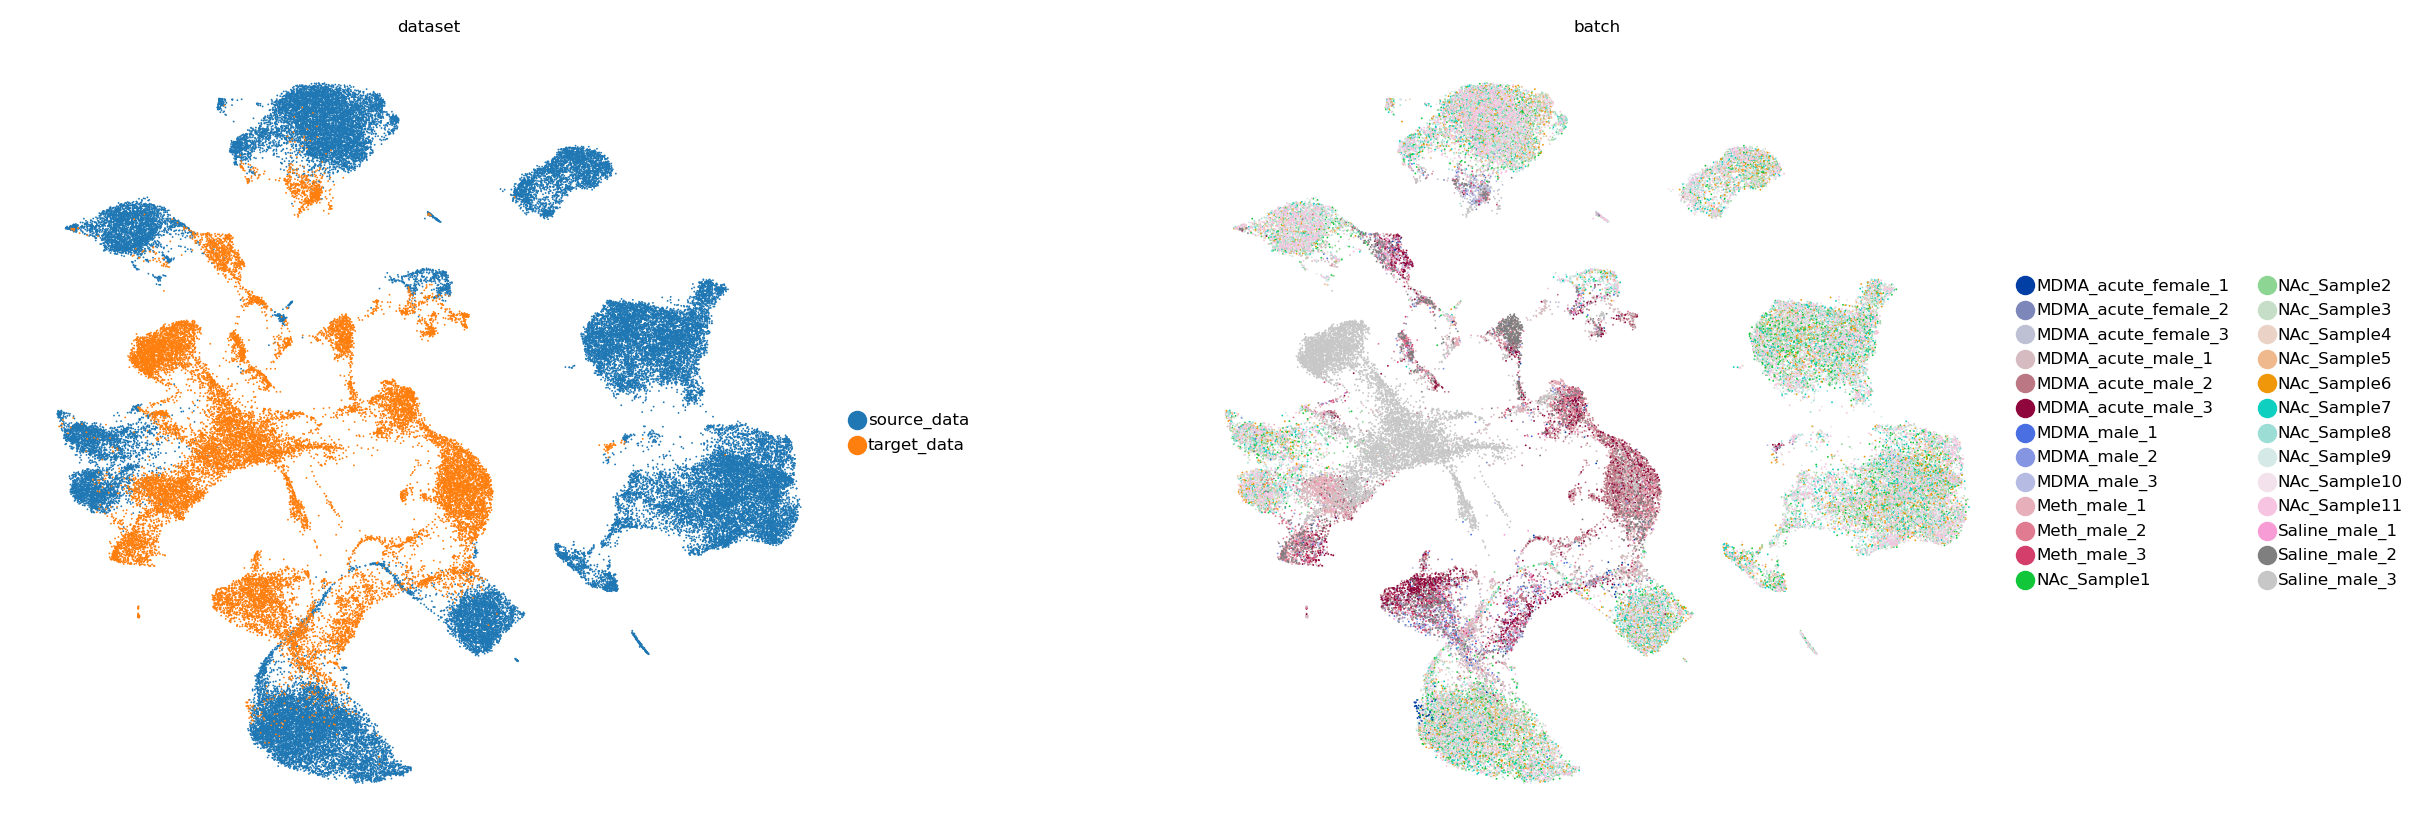

In [201]:
sc.pl.umap(
    full_latent,
    color=[
        "dataset", 'batch',
    ],
    frameon=False,
    wspace=0.3,
)
plt.show()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


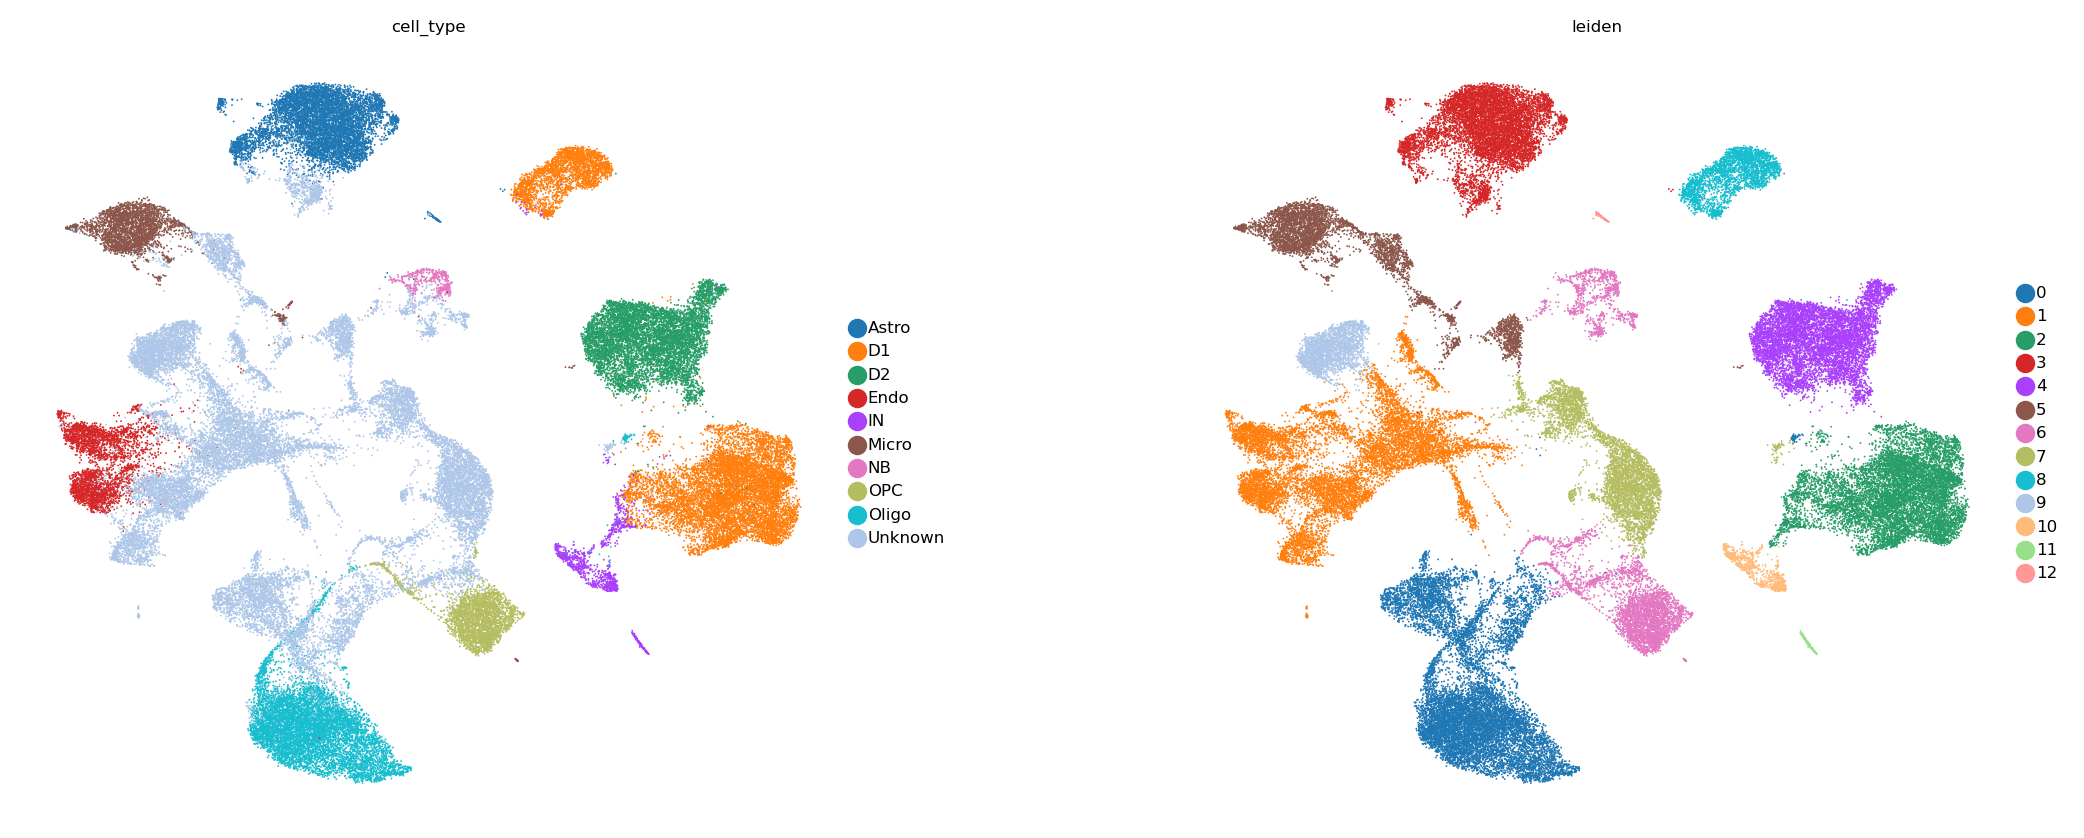

In [202]:
sc.pl.umap(
    full_latent,
    color=[
        "cell_type",'leiden',
    ],
    frameon=False,
    wspace=0.3,
)
plt.show()

In [ ]:
        "dataset", 'batch',


In [195]:
adata_annotated = sc.read_h5ad('preprocessing/adata-denoised-')

# 

___

In [ ]:
!date

In [ ]:
%